In [1]:
import sys
sys.path.append('..')

In [2]:
from src import SV_configs
from src import utils
from src import linear_RNN
from pathlib import Path
import numpy as np
from types import SimpleNamespace
import matplotlib.pyplot as plt
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.collections import LineCollection
import matplotlib
import matplotlib as mpl
from matplotlib.legend_handler import HandlerLineCollection

In [3]:
bc = utils.BlindColours()
blind_colors = bc.get_colours()
div_cmap = bc.get_div_cmap()

In [4]:
class HandlerColorLineCollection(HandlerLineCollection):
    def create_artists(self, legend, artist ,xdescent, ydescent,
                        width, height, fontsize,trans):
        x = np.linspace(0,width,self.get_numpoints(legend)+1)
        y = np.zeros(self.get_numpoints(legend)+1)+height/2.-ydescent
        points = np.array([x, y]).T.reshape(-1, 1, 2)
        segments = np.concatenate([points[:-1], points[1:]], axis=1)
        lc = LineCollection(segments, cmap=artist.cmap,
                     transform=trans)
        lc.set_array(x)
        lc.set_linewidth(artist.get_linewidth())
        return [lc]

In [5]:
def plot_task_dynamics_colors(dim, ax1, args, cmap='plasma'):
    x, y = args.D[:,dim,dim].real, args.D[:,dim,dim].imag 
    points   = np.column_stack([x, y])
    segments = np.stack([points[:-1], points[1:]], axis=1)  
    t    = np.arange(args.D.shape[0])
    norm = Normalize(vmin=t.min(), vmax=t.max())
    lc = LineCollection(segments, cmap=cmap, norm=norm) 
    lc.set_array(t)
    ax1.add_collection(lc)
    mpl_cmap = mpl.colormaps[cmap]
    colors = mpl_cmap(np.linspace(0, 1, args.D.shape[0]))
       
    ax1.plot(args.D[0,dim,dim].real,args.D[0,dim,dim].imag,'.',color='black') 
    dx = args.D[-1,dim,dim].real - args.D[-2,dim,dim].real 
    dy = args.D[-1,dim,dim].imag - args.D[-2,dim,dim].imag
    ax1.arrow(args.D[-2,dim,dim].real,args.D[-2,dim,dim].imag,dx,dy,head_width=0.1, color=colors[-2], head_length=0.1,length_includes_head=True)
    ax1.set_xlabel('real')
    ax1.set_ylabel('imaginary')
    ax1.set_xlim(-1.2,1.2)
    ax1.set_ylim(-1.2,1.2)
    ax1.axvline(x=0, color='k')
    ax1.axhline(y=0, color='k')
    return lc

In [6]:
def plot_modes(ax1, dim, angle_soln, radius_soln, recurrent=True, plot_soln=True):
    if plot_soln:
        ax1.axhline(y=angle_soln, color='gray',ls='dashed',alpha=0.7) 
        ax1.axhline(y=radius_soln, color='gray',ls='dashed',alpha=0.7, label='global solution')
    if recurrent:
        ax1.plot(np.abs(tape.recurrent_modes[0,:,dim]),color=blind_colors[0], label=r'radius ($R$)') 
        ax1.plot(np.angle(tape.recurrent_modes[0,:,dim]),color=blind_colors[1], label=r'angle ($\phi$, radians)')
        ax1.set_ylabel(r'recurrent mode ($b$)') 
    else:
        ax1.plot(np.abs(tape.input_output_modes[0,:,dim]),color=blind_colors[0], label=r'radius ($R$)') 
        ax1.plot(np.angle(tape.input_output_modes[0,:,dim]),color=blind_colors[1], label=r'angle ($\phi$, radians)')
        ax1.set_ylabel(r'input-output mode ($ac$)') 
    ax1.set_xlabel(r'training steps ($t_\theta$)')

In [7]:
args = {
    'data_out_dir' : 'data/',
    'results_out_dir' : 'results/',
    'name': 'unaligned',
    'num_seeds' : 1, 
    'override_load' : False,
    'trajectory_length' : 12,
    'num_samples' : 100,
    'num_epochs' : 5000,
    'lr' : 0.5,
    'initialization_scale' : 1e-1,
    'input_size' : 6, 
    'hidden_size' : 6, 
    'output_size' : 6,
    'S_config': ['inverse_exponential','inverse_exponential','inverse_exponential','inverse_exponential','inverse_exponential','inverse_exponential'],
    'delta' : [1, 1, 1, 1,1,1], 
    'lambda_0': [1.*np.exp((np.pi/8)*(0.+1.j)), 1*np.exp(-(np.pi/8)*(0.+1.j)), 1*np.exp((np.pi/4)*(0.+1.j)), 1*np.exp(-(np.pi/4)*(0.+1.j)), 1*np.exp((5*np.pi/4)*(0.+1.j)), 1*np.exp(-(5*np.pi/4)*(0.+1.j))],
    'S_T' : [1,1,1,1,1,1],
    'S_TeqS_t' : True,
    'zero_balanced' : True,
    'frozen_hidden_layer' : False,
    'frozen_input_output' : False,
    'single_output_y' : True,
    'inout_mode_init' : [0.01,0.01, 0.01, 0.01,0.01, 0.01],
    'in_mode_init' : [0.1,0.1, 0.1,0.1,0.1,0.1],
    'out_mode_init': [0.1,0.1,0.1,0.1,0.1,0.1],
    'rec_mode_init': [0.1,0.1,0.1,0.1,0.1,0.1], 
    'num_SV' : 6,
    'aligned_student_weights': True,
    'log_H': False,
    'log_y_hat': False,
    'compute_NTK': False,
    'nonlinear_RNN': False,
    'log_every_e_epoch': 1,
    'subsample_NTK': True,
    'subsample_H': True,
    'task_dynamics': 'diagonalized',
    'theta': None,
    'eigenspace_dynamics': True,
}
args = SimpleNamespace(**args)

In [8]:
args.D = SV_configs.create_SV_trajectories(args)
data_path = Path(args.data_out_dir) / args.name

In [9]:
data_tape = utils.get_data_tape(args)
tape = utils.get_tape_module(args)
seed = 0
utils.set_seeds(seed)
data_tape = utils.generate_eigenspace_data_multiseed(args, data_tape, seed) 
tape = utils.initialize_student_eigenspace_multiseed(args, data_tape, seed, tape)
model = linear_RNN.LinearRNN_multiseed(args, tape, seed)
model.train(data_tape.X[seed], data_tape.y[seed]) 
model.project_SVD_space(data_tape)
tape = model.tape

/Users/alex/Documents/Research/LinearRNNLearningDynamics/LRNN_dynamics/figure_notebooks copy/../src/linear_RNN.py:13: UserWarning: Casting complex values to real discards the imaginary part (Triggered internally at /private/var/folders/k1/30mswbxs7r1g6zwn8y4fyt500000gp/T/abs_5ae0635zuj/croot/pytorch-select_1700511177724/work/aten/src/ATen/native/Copy.cpp:299.)
  self.W_x = torch.tensor(copy.deepcopy(tape.W_x[seed][0]), dtype=torch.float64)


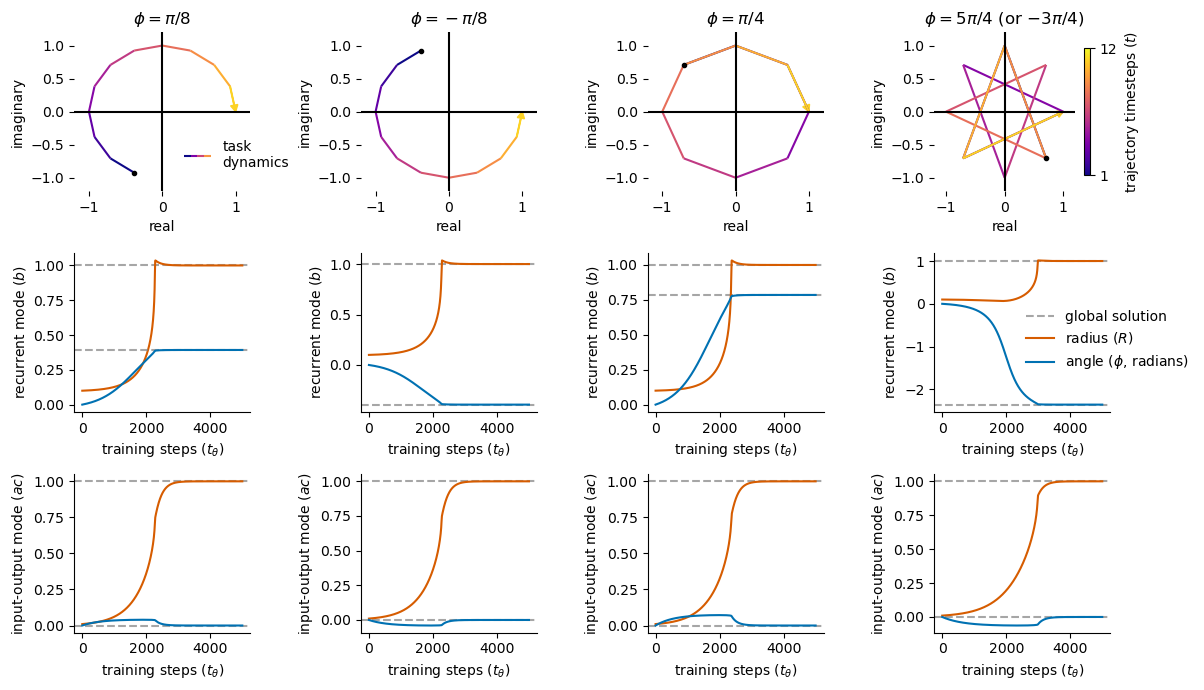

In [10]:
# Fig A10
fig = plt.figure(figsize=(12,7))

axd = fig.subplots(nrows=3, ncols=4)
for ax in axd.flat: 
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
for i in range(4):
    axd.flat[i].spines['left'].set_visible(False)
    axd.flat[i].spines['bottom'].set_visible(False)

cmap = 'plasma'

lc = plot_task_dynamics_colors(0, axd.flat[0], args, cmap)
axd.flat[0].legend([lc], [f"task\ndynamics"], handler_map={lc: HandlerColorLineCollection(numpoints=4)},frameon=False,bbox_to_anchor=(0.55,0.4))
        
axd.flat[0].set_title(r'$\phi=\pi/8$')
lc = plot_task_dynamics_colors(1, axd.flat[1], args, cmap)
axd.flat[1].set_title(r'$\phi=-\pi/8$')

#pi/8
lc = plot_task_dynamics_colors(2, axd.flat[2], args, cmap)
axd.flat[2].set_title(r'$\phi=\pi/4$')

# #3pi/2
lc = plot_task_dynamics_colors(4, axd.flat[3], args, cmap)
axd.flat[3].set_title(r'$\phi=5\pi/4$ (or $-3\pi/4)$')

t    = np.arange(args.D.shape[0])
norm = Normalize(vmin=t.min(), vmax=t.max())
im = matplotlib.cm.ScalarMappable(norm=norm, cmap=cmap)
cbar = fig.colorbar(im, ax=axd.flat[3], shrink=0.8, label=r'trajectory timesteps ($t$)',ticks=[0,11])
cbar.ax.set_yticklabels(['1', '12']) 

dim = 0
axd.flat[4].axhline(y=1, color='gray',ls='dashed',alpha=0.7, label='global solution')
axd.flat[4].plot(np.abs(tape.recurrent_modes[0,:,dim]),color=blind_colors[0], label=r'radius ($R$)') 
axd.flat[4].set_xlabel(r'training steps ($t_\theta$)')
axd.flat[4].axhline(y=np.pi/8, color='gray',ls='dashed',alpha=0.7)
axd.flat[4].plot(np.angle(tape.recurrent_modes[0,:,dim]),color=blind_colors[1], label=r'angle ($\phi$, radians)') 
axd.flat[4].set_ylabel(r'recurrent mode ($b$)') 
axd.flat[4].set_xlabel(r'training steps ($t_\theta$)')

axd.flat[8].axhline(y=1, color='gray',ls='dashed',alpha=0.7, label='global solution')
axd.flat[8].axhline(y=0, color='gray',ls='dashed',alpha=0.7)
axd.flat[8].plot(np.abs(tape.input_output_modes[0,:,dim]),color=blind_colors[0], label=r'radius ($R$)') 
axd.flat[8].set_xlabel(r'training steps ($t_\theta$)')
axd.flat[8].plot(np.angle(tape.input_output_modes[0,:,dim]),color=blind_colors[1], label=r'angle ($\phi$, radians)') 
axd.flat[8].set_ylabel(r'input-output mode ($ac$)') 
axd.flat[8].set_xlabel(r'training steps ($t_\theta$)')

dim = 1
axd.flat[5].axhline(y=1, color='gray',ls='dashed',alpha=0.7)
axd.flat[5].axhline(y=-np.pi/8, color='gray',ls='dashed',alpha=0.7)
axd.flat[5].plot(np.abs(tape.recurrent_modes[0,:,dim]),color=blind_colors[0]) 
axd.flat[5].plot(np.angle(tape.recurrent_modes[0,:,dim]),color=blind_colors[1]) 
axd.flat[5].set_xlabel(r'training steps ($t_\theta$)')
axd.flat[5].set_ylabel(r'recurrent mode ($b$)') 

axd.flat[9].axhline(y=1, color='gray',ls='dashed',alpha=0.7, label='global solution')
axd.flat[9].axhline(y=0, color='gray',ls='dashed',alpha=0.7)
axd.flat[9].plot(np.abs(tape.input_output_modes[0,:,dim]),color=blind_colors[0], label=r'radius ($R$)') 
axd.flat[9].set_xlabel(r'training steps ($t_\theta$)')
axd.flat[9].plot(np.angle(tape.input_output_modes[0,:,dim]),color=blind_colors[1], label=r'angle ($\phi$, radians)') 
axd.flat[9].set_ylabel(r'input-output mode ($ac$)') 
axd.flat[9].set_xlabel(r'training steps ($t_\theta$)')

dim = 2
axd.flat[6].axhline(y=1, color='gray',ls='dashed',alpha=0.7)
axd.flat[6].axhline(y=np.pi/4, color='gray',ls='dashed',alpha=0.7)
axd.flat[6].plot(np.abs(tape.recurrent_modes[0,:,dim]),color=blind_colors[0]) 
axd.flat[6].plot(np.angle(tape.recurrent_modes[0,:,dim]),color=blind_colors[1]) 
axd.flat[6].set_xlabel(r'training steps ($t_\theta$)')
axd.flat[6].set_ylabel(r'recurrent mode ($b$)') 

axd.flat[10].axhline(y=1, color='gray',ls='dashed',alpha=0.7, label='global solution')
axd.flat[10].axhline(y=0, color='gray',ls='dashed',alpha=0.7)
axd.flat[10].plot(np.abs(tape.input_output_modes[0,:,dim]),color=blind_colors[0], label=r'radius ($R$)') 
axd.flat[10].set_xlabel(r'training steps ($t_\theta$)')
axd.flat[10].plot(np.angle(tape.input_output_modes[0,:,dim]),color=blind_colors[1], label=r'angle $\phi$ (radians)') 
axd.flat[10].set_ylabel(r'input-output mode ($ac$)') 
axd.flat[10].set_xlabel(r'training steps ($t_\theta$)')

dim = 4
axd.flat[7].axhline(y=1, color='gray',ls='dashed',alpha=0.7, label='global solution')
axd.flat[7].axhline(y=-(2*np.pi-5*np.pi/4), color='gray',ls='dashed',alpha=0.7)
axd.flat[7].plot(np.abs(tape.recurrent_modes[0,:,dim]),color=blind_colors[0], label=r'radius ($R$)') 
axd.flat[7].plot(np.angle(tape.recurrent_modes[0,:,dim]),color=blind_colors[1], label=r'angle ($\phi$, radians)') 
axd.flat[7].set_xlabel(r'training steps ($t_\theta$)')
axd.flat[7].set_ylabel(r'recurrent mode ($b$)') 
axd.flat[7].legend(frameon=False,bbox_to_anchor=(0.45,0.45))

axd.flat[11].axhline(y=1, color='gray',ls='dashed',alpha=0.7, label='global solution')
axd.flat[11].axhline(y=0, color='gray',ls='dashed',alpha=0.7)
axd.flat[11].plot(np.abs(tape.input_output_modes[0,:,dim]),color=blind_colors[0], label=r'radius ($R$)') 
axd.flat[11].set_xlabel(r'training steps ($t_\theta$)')
axd.flat[11].plot(np.angle(tape.input_output_modes[0,:,dim]),color=blind_colors[1], label=r'angle ($\phi$, radians)') 
axd.flat[11].set_ylabel(r'input-output mode ($ac$)') 
axd.flat[11].set_xlabel(r'training steps ($t_\theta$)')
fig.tight_layout()
# fig.savefig('paper_figs/rotations_angle_change_v2.svg', dpi=300, transparent=True, bbox_inches='tight')
# fig.savefig('paper_figs/rotations_angle_change_v2.png', dpi=300, transparent=True, bbox_inches='tight')
# fig.savefig('paper_figs/rotations_angle_change_v2.pdf', dpi=300, transparent=True, bbox_inches='tight')

In [11]:
args = {
    'data_out_dir' : 'data/',
    'results_out_dir' : 'results/',
    'name': 'unaligned',
    'num_seeds' : 1, 
    'override_load' : False,
    'trajectory_length' : 15,
    'num_samples' : 200, #100,
    'num_epochs' : 6000,
    'lr' : 1.5,
    'initialization_scale' : 1e-1,
    'input_size' : 8, 
    'hidden_size' : 8, 
    'output_size' : 8,
    'S_config': ['inverse_exponential','inverse_exponential','inverse_exponential','inverse_exponential','inverse_exponential','inverse_exponential','inverse_exponential','inverse_exponential'],
    'delta' : [1., 1., 1., 1.,1,1,1,1],  
    'lambda_0': [0.4*np.exp((np.pi/6)*(0.+1.j)), 0.4*np.exp(-(np.pi/6)*(0.+1.j)), 0.9*np.exp((np.pi/6)*(0.+1.j)), 0.9*np.exp(-(np.pi/6)*(0.+1.j)), 1.0*np.exp((np.pi/6)*(0.+1.j)), 1.0*np.exp(-(np.pi/6)*(0.+1.j)),1.05*np.exp((np.pi/6)*(0.+1.j)), 1.05*np.exp(-(np.pi/6)*(0.+1.j))],
    'S_T' : [1,1,1,1,1,1,1,1],
    'S_TeqS_t' : True,
    'zero_balanced' : True,
    'frozen_hidden_layer' : False,
    'frozen_input_output' : False,
    'single_output_y' : True,
    'inout_mode_init' : [0.01,0.01, 0.01, 0.01,0.01, 0.01,0.01, 0.01],
    'in_mode_init' : [0.1,0.1, 0.1,0.1,0.1,0.1,0.1,0.1],
    'out_mode_init': [0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1],
    'rec_mode_init': [0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1], 
    'num_SV' : 8,
    'aligned_student_weights': True,
    'log_H': False,
    'log_y_hat': False,
    'compute_NTK': False,
    'nonlinear_RNN': False,
    'log_every_e_epoch': 1,
    'subsample_NTK': True,
    'subsample_H': True,
    'task_dynamics': 'diagonalized',
    'theta': None,
    'eigenspace_dynamics': True,
}
args = SimpleNamespace(**args)

In [12]:
args.D = SV_configs.create_SV_trajectories(args)
data_path = Path(args.data_out_dir) / args.name

In [13]:
data_tape = utils.get_data_tape(args)
tape = utils.get_tape_module(args)
seed = 0
utils.set_seeds(seed)
data_tape = utils.generate_eigenspace_data_multiseed(args, data_tape, seed) 
tape = utils.initialize_student_eigenspace_multiseed(args, data_tape, seed, tape)
model = linear_RNN.LinearRNN_multiseed(args, tape, seed)
model.train(data_tape.X[seed], data_tape.y[seed]) 
model.project_SVD_space(data_tape)
tape = model.tape

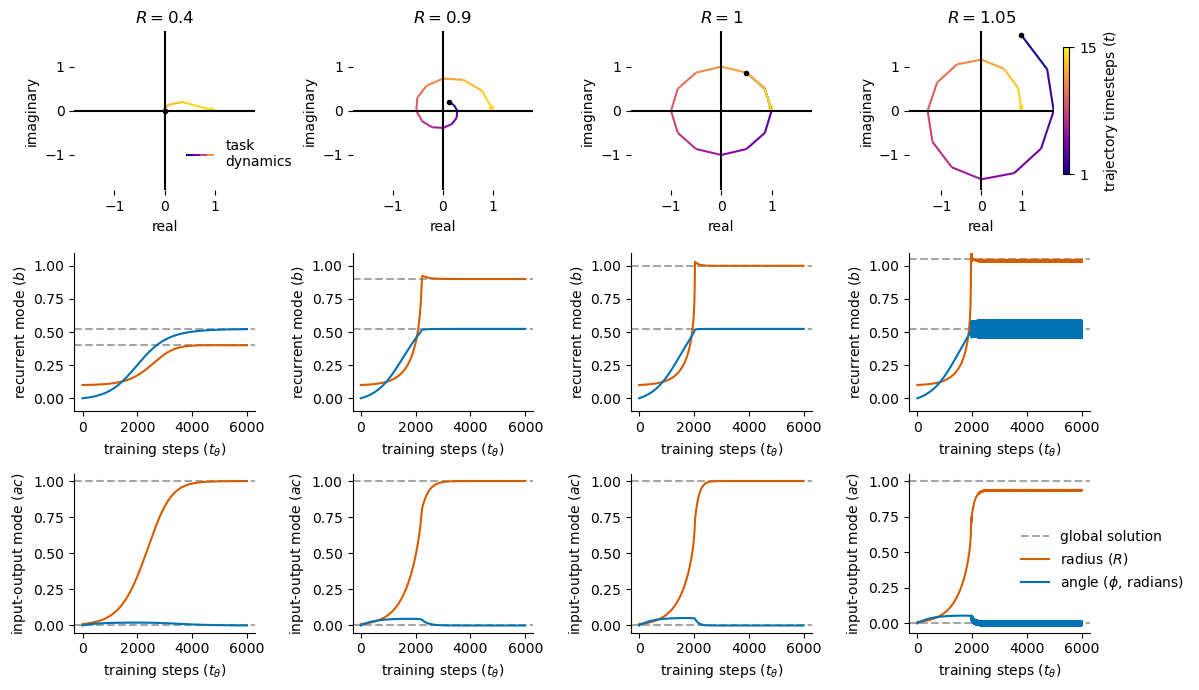

In [14]:
# Fig A11
fig = plt.figure(figsize=(12,7))

axd = fig.subplots(nrows=3, ncols=4)
for ax in axd.flat: 
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
for i in range(4):
    axd.flat[i].spines['left'].set_visible(False)
    axd.flat[i].spines['bottom'].set_visible(False)

cmap = 'plasma'

lc = plot_task_dynamics_colors(0, axd.flat[0], args, cmap)
axd.flat[0].set_title(r'$R=0.4$')
axd.flat[0].set_xlim(-1.8,1.8)
axd.flat[0].set_ylim(-1.8,1.8)
axd.flat[0].legend([lc], [f"task\ndynamics"], handler_map={lc: HandlerColorLineCollection(numpoints=4)},frameon=False,bbox_to_anchor=(0.55,0.4))

lc = plot_task_dynamics_colors(2, axd.flat[1], args, cmap)
axd.flat[1].set_xlim(-1.8,1.8)
axd.flat[1].set_ylim(-1.8,1.8)
axd.flat[1].set_title(r'$R=0.9$')

lc = plot_task_dynamics_colors(4, axd.flat[2], args, cmap)
axd.flat[2].set_title(r'$R=1$')
axd.flat[2].set_xlim(-1.8,1.8)
axd.flat[2].set_ylim(-1.8,1.8)

lc = plot_task_dynamics_colors(6, axd.flat[3], args, cmap)
axd.flat[3].set_title(r'$R=1.05$')
axd.flat[3].set_xlim(-1.8,1.8)
axd.flat[3].set_ylim(-1.8,1.8)

t    = np.arange(args.D.shape[0])
norm = Normalize(vmin=t.min(), vmax=t.max())
im = matplotlib.cm.ScalarMappable(norm=norm, cmap=cmap)
cbar = fig.colorbar(im, ax=axd.flat[3], shrink=0.8, label=r'trajectory timesteps ($t$)',ticks=[0,14])
cbar.ax.set_yticklabels(['1', '15']) 

dim = 0 
plot_modes(axd.flat[4], dim, np.pi/6, 0.4, recurrent=True)
plot_modes(axd.flat[8], dim, 0, 1, recurrent=False)
axd.flat[4].set_ylim(-0.1,1.1)

dim = 2 
plot_modes(axd.flat[5], dim, np.pi/6, 0.9, recurrent=True)
plot_modes(axd.flat[9], dim, 0, 1, recurrent=False)
axd.flat[5].set_ylim(-0.1,1.1)

dim = 4
plot_modes(axd.flat[6], dim, np.pi/6, 1.0, recurrent=True)
plot_modes(axd.flat[10], dim, 0, 1, recurrent=False)
axd.flat[6].set_ylim(-0.1,1.1)

dim =  6 
plot_modes(axd.flat[7], dim, np.pi/6, 1.05, recurrent=True)
plot_modes(axd.flat[11], dim, 0, 1, recurrent=False)
axd.flat[7].set_ylim(-0.1,1.1)
axd.flat[11].legend(frameon=False,bbox_to_anchor=(0.55,0.45))
fig.tight_layout()
# fig.savefig('paper_figs/rotations_radius_change_v2.svg', dpi=300, transparent=True, bbox_inches='tight')
# fig.savefig('paper_figs/rotations_radius_change_v2.png', dpi=300, transparent=True, bbox_inches='tight')
# fig.savefig('paper_figs/rotations_radius_change_v2.pdf', dpi=300, transparent=True, bbox_inches='tight')

In [15]:
args = {
    'data_out_dir' : 'data/',
    'results_out_dir' : 'results/',
    'name': 'unaligned',
    'num_seeds' : 1, 
    'override_load' : False,
    'trajectory_length' : 8,
    'num_samples' : 100,
    'num_epochs' : 5000,
    'lr' : 1,
    'initialization_scale' : 1e-1,
    'input_size' : 6, 
    'hidden_size' : 6, 
    'output_size' : 6,
    'S_config': ['inverse_exponential','inverse_exponential','exponential','exponential','constant','constant'],
    'delta' : [1, 1, 1,1,1,1], 
    'lambda_0': [0.9*np.exp((np.pi/6)*(0.+1.j)), 0.9*np.exp(-(np.pi/6)*(0.+1.j)), 1.05*np.exp((np.pi/6)*(0.+1.j)), 1.05*np.exp(-(np.pi/6)*(0.+1.j)), 0.7*np.exp((np.pi/6)*(0.+1.j)), 0.7*np.exp(-(np.pi/6)*(0.+1.j))],
    'S_T' : [1,1,1,1,1,1],
    'S_TeqS_t' : True,
    'zero_balanced' : True,
    'frozen_hidden_layer' : False,
    'frozen_input_output' : False,
    'single_output_y' : True,
    'inout_mode_init' : [0.01,0.01, 0.01, 0.01,0.01, 0.01],
    'in_mode_init' : [0.1,0.1, 0.1,0.1,0.1,0.1],
    'out_mode_init': [0.1,0.1,0.1,0.1,0.1,0.1],
    'rec_mode_init': [0.1,0.1,0.1,0.1,0.1,0.1], 
    'num_SV' : 6,
    'aligned_student_weights': True,
    'log_H': False,
    'log_y_hat': False,
    'compute_NTK': False,
    'nonlinear_RNN': False,
    'log_every_e_epoch': 1,
    'subsample_NTK': True,
    'subsample_H': True,
    'task_dynamics': 'diagonalized',
    'theta': None,
    'eigenspace_dynamics': True,
}
args = SimpleNamespace(**args)

In [16]:
args.D = SV_configs.create_SV_trajectories(args)
data_path = Path(args.data_out_dir) / args.name

In [17]:
data_tape = utils.get_data_tape(args)
tape = utils.get_tape_module(args)
seed = 0
utils.set_seeds(seed)
data_tape = utils.generate_eigenspace_data_multiseed(args, data_tape, seed) 
tape = utils.initialize_student_eigenspace_multiseed(args, data_tape, seed, tape)
model = linear_RNN.LinearRNN_multiseed(args, tape, seed)
model.train(data_tape.X[seed], data_tape.y[seed]) 
model.project_SVD_space(data_tape)
tape = model.tape

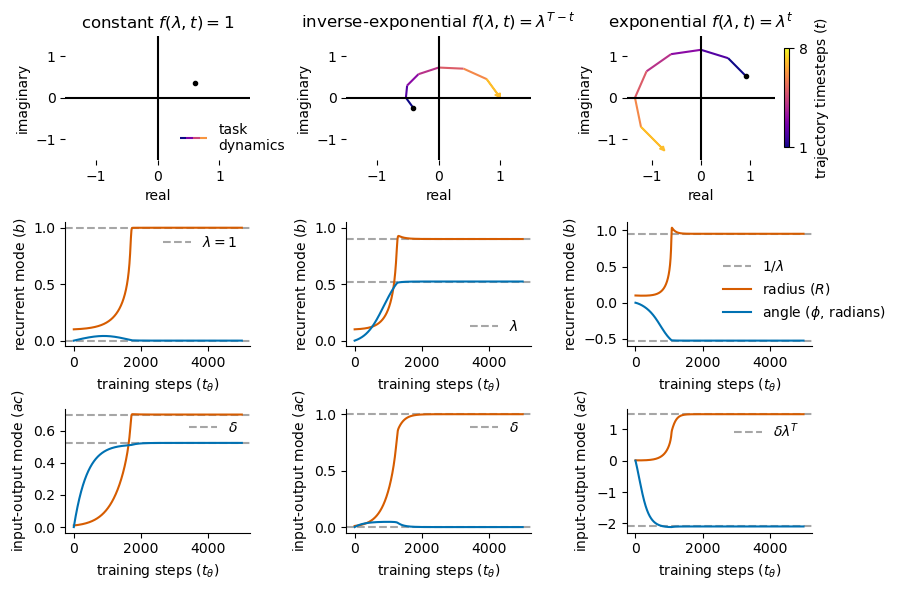

In [18]:
# Fig A9
fig = plt.figure(figsize=(9,6))

axd = fig.subplots(nrows=3, ncols=3)
for ax in axd.flat: 
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
for i in range(3):
    axd.flat[i].spines['left'].set_visible(False)
    axd.flat[i].spines['bottom'].set_visible(False)

cmap = 'plasma'

lc = plot_task_dynamics_colors(4, axd.flat[0], args, cmap)
axd.flat[0].legend([lc], [f"task\ndynamics"], handler_map={lc: HandlerColorLineCollection(numpoints=4)},frameon=False,bbox_to_anchor=(0.55,0.4))
axd.flat[0].set_title(r'constant $f(\lambda,t)=1$')


lc = plot_task_dynamics_colors(0, axd.flat[1], args, cmap)
axd.flat[1].set_title(r'inverse-exponential $f(\lambda,t)=\lambda^{T-t}$')

#pi/8
lc = plot_task_dynamics_colors(2, axd.flat[2], args, cmap)
axd.flat[2].set_title(r'exponential $f(\lambda,t)=\lambda^t$')

axd.flat[0].set_ylim(-1.5,1.5)
axd.flat[1].set_ylim(-1.5,1.5)
axd.flat[2].set_ylim(-1.5,1.5)
axd.flat[0].set_xlim(-1.5,1.5)
axd.flat[1].set_xlim(-1.5,1.5)
axd.flat[2].set_xlim(-1.5,1.5)

t    = np.arange(args.D.shape[0])
norm = Normalize(vmin=t.min(), vmax=t.max())
im = matplotlib.cm.ScalarMappable(norm=norm, cmap=cmap)
cbar = fig.colorbar(im, ax=axd.flat[2], shrink=0.8, label=r'trajectory timesteps ($t$)',ticks=[0,7])
cbar.ax.set_yticklabels(['1', '8']) 

# constant
dim = 4
axd.flat[3].axhline(y=0, color='gray',ls='dashed',alpha=0.7) 
axd.flat[3].axhline(y=1.0, color='gray',ls='dashed',alpha=0.7, label=r'$\lambda=1$')
axd.flat[3].legend(frameon=False)#,bbox_to_anchor=(0.45,0.45))
plot_modes(axd.flat[3], dim, 0, 1.0, recurrent=True, plot_soln=False)
axd.flat[6].axhline(y=np.pi/6, color='gray',ls='dashed',alpha=0.7) 
axd.flat[6].axhline(y=0.7, color='gray',ls='dashed',alpha=0.7, label=r'$\delta$')
axd.flat[6].legend(frameon=False)
plot_modes(axd.flat[6], dim, np.pi/6, 0.7, recurrent=False, plot_soln=False)

# inverse-exponential
dim = 0
axd.flat[4].axhline(y=np.pi/6, color='gray',ls='dashed',alpha=0.7) 
axd.flat[4].axhline(y=0.9, color='gray',ls='dashed',alpha=0.7, label=r'$\lambda$')
axd.flat[4].legend(frameon=False)
plot_modes(axd.flat[4], dim, np.pi/6, 0.9, recurrent=True, plot_soln=False)
axd.flat[4].set_ylim(-0.05,1.05)
axd.flat[7].axhline(y=0, color='gray',ls='dashed',alpha=0.7) 
axd.flat[7].axhline(y=1, color='gray',ls='dashed',alpha=0.7, label=r'$\delta$')
axd.flat[7].legend(frameon=False)
plot_modes(axd.flat[7], dim, 0, 1, recurrent=False, plot_soln=False)

# exponential
dim = 2
axd.flat[5].axhline(y=-(np.pi/6), color='gray',ls='dashed',alpha=0.7) 
axd.flat[5].axhline(y=1/1.05, color='gray',ls='dashed',alpha=0.7, label=r'$1/\lambda$')
axd.flat[5].legend(frameon=False)
plot_modes(axd.flat[5], dim, -(np.pi/6), 1/1.05, recurrent=True, plot_soln=False)
axd.flat[5].legend(frameon=False,bbox_to_anchor=(0.45,0.45))
axd.flat[8].axhline(y=-((2*np.pi)-(8*np.pi/6)), color='gray',ls='dashed',alpha=0.7) 
axd.flat[8].axhline(y=1.05**8, color='gray',ls='dashed',alpha=0.7, label=r'$\delta \lambda^T$')
axd.flat[8].legend(frameon=False)
plot_modes(axd.flat[8], dim, -((2*np.pi)-(8*np.pi/6)), 1.05**8, recurrent=False, plot_soln=False)

fig.tight_layout()
# fig.savefig('paper_figs/rotations_taskdyn_change_v2.svg', dpi=300, transparent=True, bbox_inches='tight')
# fig.savefig('paper_figs/rotations_taskdyn_change_v2.png', dpi=300, transparent=True, bbox_inches='tight')
# fig.savefig('paper_figs/rotations_taskdyn_change_v2.pdf', dpi=300, transparent=True, bbox_inches='tight')